In [16]:
import os
import sys

import joblib
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator

sys.path.insert(0, '../../..')
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.dbscan_detector import DBSCANDetector
from utils.metrics import show_feature_extraction_metrics
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'DBSCAN'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True

In [17]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [18]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


In [19]:
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = ['x', 'y', 'z']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 2174.88it/s]

Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


# DBSCAN 
O DBSCAN não sabe o que é o DTW, somente distâncias numéricas. Então, para fazer o DBSCAN tenho de lhe passar uma matriz de distâncias já calculadas.plot_movement_data

In [20]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

total_samples = len(results_temp_base)                                  
total_trials  = len(df_filtered[['sub', 'repID']].drop_duplicates())
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100

if total_samples != X_movement.shape[0]:
    raise ValueError(f"⚠️ CRITICAL ERROR: Metadata ({total_samples}) does not match the Matrix ({X_movement.shape[0]})!")

print(f"✅ Perfect Synchronization! Rows in Matrix: {X_movement.shape[0]} | Rows in Metadata: {total_samples}")
print(f"Total samples in the Matrix: {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(f"Minimum confirmed outlier rate in the CSV (Sub + RepID + movID): {percentagem_conhecida:.2f}%")

✅ Perfect Synchronization! Rows in Matrix: 95 | Rows in Metadata: 95
Total samples in the Matrix: 95
Total unique repetitions analyzed (Move): 95
Minimum confirmed outlier rate in the CSV (Sub + RepID + movID): 5.26%


## Grid Search

### Calculate Kneedle for each fold

In [21]:
unique_subjects = results_temp_base['sub'].unique()
min_samples_range = [3, 4, 5, 7, 10]

fold_param_grids = {}

def make_dbscan_grid_fn(metric='precomputed', k=4, rel_width=0.15, n_eps=20,
                        min_samples_range=(3, 4, 5, 7, 10)):
    def grid_fn(X_train):
        nbrs = NearestNeighbors(n_neighbors=k, metric=metric).fit(X_train)
        distances, _ = nbrs.kneighbors(X_train)
        k_dist = np.sort(distances[:, k - 1])

        knee = KneeLocator(range(len(k_dist)), k_dist, curve='convex', direction='increasing')
        eps0 = knee.elbow_y
        if eps0 is None:                        # No knee found, fallback to mean
            print("⚠️ Kneedle sem cotovelo, fallback para a média")
            eps0 = float(np.mean(k_dist))

        # Generate a range of eps values around the knee point
        eps_range = np.unique(np.round(np.linspace(eps0 * (1 - rel_width), eps0 * (1 + rel_width), n_eps), 4))
        return [{'eps': float(e), 'min_samples': m}
                for e, m in itertools.product(eps_range, min_samples_range)]
    return grid_fn

In [22]:
matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.wrist_only_constrained_dtw_distance_matrix)

loso_results = run_loso_evaluation(
    detector_class=DBSCANDetector, 
    param_grid=make_dbscan_grid_fn(metric='precomputed'),
    data_matrix=matrices[0.5], # TODO placeholder, replaced per fold
    metadata_df=results_temp_base,
    known_outliers_df=outliers_csv,
    metric_type='precomputed',
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    dtw_matrices=matrices
)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

print("\nSearch Results:")
print("Teste", f"MCC={loso_results['MCC']:.3f}", f"Rej={loso_results['Rejection_Rate']:.1f}%",
          f"AUROC={loso_results['AUROC']:.3f}")

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.620 Rej=12.6% AUROC=nan


### Statistic Evaluation - Bootstraping

In [23]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [24]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_CSV_SHAPE_BASED_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for DBSCAN - ShapeBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 12
Rejection Rate: 12.63%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  5
Total False Positives (Global): 7
Total False Negatives (Global): 0
Total True Negatives (Global):  83
------------------------------
Blind Precision: 41.67 [12.98–100.00]
Blind Recall:    100.00 [100.00–100.00]
Blind F1-Score:  58.82
Blind F2-Score:  78.12 [42.71–100.00]
Blind MCC:       0.62 [0.34–1.00]
Blind AUPRC:     N/A (detector has no continuous score_blind, or no known positives)
Blind AUROC:     N/A

Total Tuning Time (19 Subjects): 7.2611s
Total Inference Time (19 Subjects): 0.0194s

Overall Best Parameters (Most frequent across folds):
   {'eps': 710.2625, 'min_samples': 3}
Occurrences: 13


## Treinar Modelo Final

In [25]:
best_params = loso_results['Best_Params']
best_eps = best_params['eps']
best_min_samples = best_params['min_samples']

selected_radius = loso_results['Most_Frequent_DTW_Radius']
selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier

In [26]:
dbscan_model = DBSCAN(eps=best_eps,min_samples=best_min_samples, metric='precomputed')
labels = dbscan_model.fit_predict(selected_dtw_matrix)
joblib.dump(dbscan_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))


outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)

In [27]:
# Reconstruct matadata to join with the original CSV
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0) # shape (n_samples - n_outliers, T, n_features)
X_movement_outliers = X_movement[outlier_indices] # shape (n_outliers, T, n_features)

print(f"Raw Outlier Trials Detected: {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers/total_trials*100):.2f}%")
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected: 5
Unique Outlier Trials Detected: 5
Detected Outlier Percentage (sub + repID + movID): 5.26%
Detected Outlier Percentage (sub + repID): 5.26%


In [28]:
real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Outlier Details:")
print(real_outliers_info)

Outlier Details:
    sub  repID  movID movLabel
6     2      2      9     Move
15    4      1      9     Move
30    7      1      9     Move
50   11      1      9     Move
55   12      1      9     Move


In [29]:
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 5
False Positives (Identified, not in CSV): 0
False Negatives (In CSV, not identified): 0
True Negatives (Normal, stayed normal): 90
--------------------------------------------------
Missing outliers (In CSV, not identified):
Empty DataFrame
Columns: [sub, repID]
Index: []

Precision (False Positives): 5/5 (100.00%)
Recall (True Positive Rate): 5/5 (100.00%)
F1-Score: 100.00%
F2-Score: 100.00%


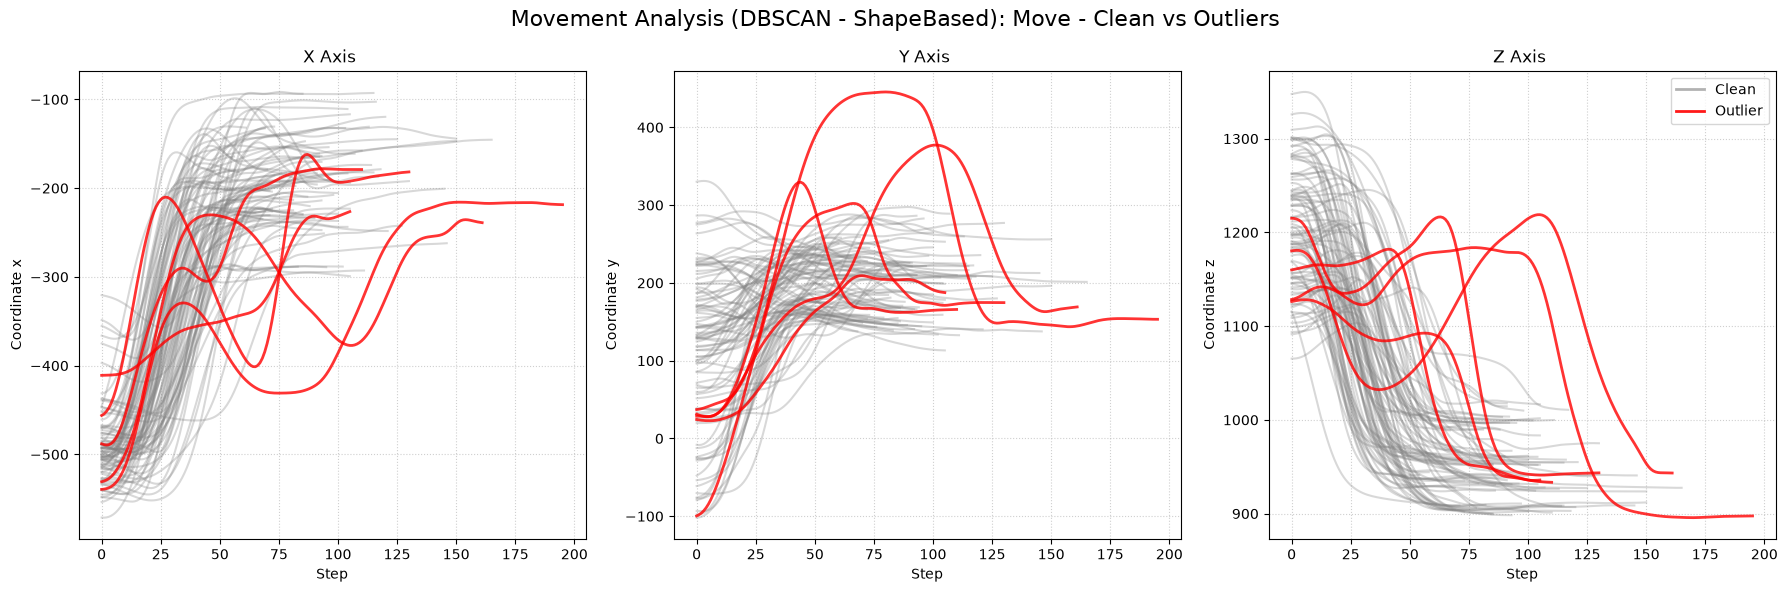

In [30]:
plot_movement_data(
    clean_data=X_movement_clean,
    outlier_data=X_movement_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)